# Introduction à NumPy
**Parcours structuré du chapitre 2**

Cycle Ingénieur / M1  Cours interactif (1h+)

## Objectifs

- Comprendre **pourquoi** NumPy est rapide (organisation mémoire, SIMD, vectorisation)
- Savoir **créer** et **inspecter** des tableaux n-dimensionnels
- Maétriser l'**indexation**, le **slicing** et la différence **view vs copy**
- Reshaper, empiler et diffuser (broadcasting) de maniére efficace
- Utiliser ufuncs, masques, tri, fancy indexing et structures
- Appliquer des **statistiques** é des données réelles et synthétiques

## Plan de la séance

1. Motivation et coût de Python
2. Types et création de tableaux
3. Attributs et organisation en mémoire
4. Indexation, slicing et vues
5. Reshape et concaténation
6. Ufuncs et vectorisation
7. Agrégations et statistiques (données réelles)
8. Broadcasting
9. Masques booléens
10. Fancy indexing
11. Tri et partition
12. Données structurées
13. Exercices et synthése

# 1. Motivation : le coût de Python

## Qu’est-ce que NumPy ?

**NumPy** (Numerical Python) est la bibliothèque fondamentale
du calcul numérique en Python.

Elle fournit :
- un **tableau multidimensionnel** efficace (`ndarray`)
- des **opérations vectorisées** rapides
- des outils pour le **calcul scientifique et l’analyse de données**

NumPy permet d’écrire du code **clair, concis et performant**
pour manipuler de grands volumes de données numériques.


## Un entier Python est un objet « riche »

En Python, un entier n’est **pas** un simple nombre en mémoire.  
C’est un **objet complet** qui contient :

- le type de l’objet
- des compteurs de référence
- des métadonnées internes

Par exemple, un entier Python (`x = 10000`) correspond à une structure similaire à :

```c
struct _longobject {
    long ob_refcnt;        // compteur de références
    PyTypeObject *ob_type; // type de l’objet
    size_t ob_size;        // taille des données
    long ob_digit[1];      // valeur de l’entier
};

➡️ Cette flexibilité a un **coût mémoire important**, surtout lorsque l’on manipule de grandes quantités de données numériques.

NumPy adopte une approche différente :  
les valeurs sont stockées dans des **tableaux homogènes**, sans surcoût par élément.

In [3]:
import sys
import numpy as np

# Entier Python
py_int = 7
print("Taille d'un int Python :", sys.getsizeof(py_int), "octets")

# Liste Python d'entiers
py_list = list(range(10))
print("\nListe Python (10 entiers) :")
print(" Taille de la liste       :", sys.getsizeof(py_list), "octets")
print(" Taille d'un élément     :", sys.getsizeof(py_list[0]), "octets")

# Tableau NumPy
np_array = np.arange(10, dtype=np.int32)
print("\nTableau NumPy int32 (10 éléments) :")
print(" Taille des données      :", np_array.nbytes, "octets")
print(" Taille par élément      :", np_array.itemsize, "octets")
print(" dtype                   :", np_array.dtype)


Taille d'un int Python : 28 octets

Liste Python (10 entiers) :
 Taille de la liste       : 136 octets
 Taille d'un élément     : 24 octets

Tableau NumPy int32 (10 éléments) :
 Taille des données      : 40 octets
 Taille par élément      : 4 octets
 dtype                   : int32


## Idée clé

### Listes Python vs tableaux NumPy

**Listes Python**
- références vers des objets
- types potentiellement différents
- données dispersées en mémoire

**Tableaux NumPy**
- données **contiguës**
- **dtype unique**
- structure optimisée pour le calcul

➡️ Résultat :
- accès mémoire rapides
- cache CPU efficace
- vectorisation (SIMD)
- très hautes performances


## Boucles Python vs vectorisation

**Objectif**  
Comparer une implémentation naïve en Python avec une version vectorisée en NumPy.

**Problème étudié**  
Calculer la **somme des carrés** d’un tableau de valeurs.

In [4]:
import numpy as np

n = 1_000_000
py_list = list(range(n))
np_array = np.arange(n, dtype=np.int64)

# 1) Boucle Python explicite
def python_loop(data):
    s = 0
    for x in data:
        s += x * x
    return s

# 2) Générateur Python (toujours une boucle)
def python_generator(data):
    return sum(x * x for x in data)

# 3) Vectorisation NumPy
def numpy_vectorized(arr):
    return np.sum(arr * arr)

%timeit python_loop(py_list)
%timeit python_generator(py_list)
%timeit numpy_vectorized(np_array)


59.3 ms ± 948 µs per loop (mean ± std. dev. of 7 runs, 10 loops each)
65.7 ms ± 3.94 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
1.1 ms ± 19.7 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


# 2. Types et création de tableaux

## Dtypes : précision, plage de valeurs et mémoire
Le **dtype** définit :
- la **taille en mémoire** de chaque élément (ex. `int32` = 4 octets, `int64` = 8 octets)
- la **plage de valeurs** et/ou la **précision** (pour les floats)

➡️ Choisir un dtype adapté permet de **réduire la RAM** et parfois **d’accélérer** certains calculs, sans perdre l’information utile.

In [9]:
import numpy as np

# 1) Coût mémoire : int32 vs int64
n = 1_000_000
a32 = np.ones(n, dtype=np.int32)
a64 = np.ones(n, dtype=np.int64)

print("Mémoire (1 million d'entiers) :")
print(" int32 :", a32.nbytes / 1e6, "MB  | itemsize =", a32.itemsize, "octets")
print(" int64 :", a64.nbytes / 1e6, "MB  | itemsize =", a64.itemsize, "octets")

# 2) Plage de valeurs (attention aux débordements)
print("\nPlage de valeurs :")
print(" int32 :", np.iinfo(np.int32).min, "→", np.iinfo(np.int32).max)
print(" int64 :", np.iinfo(np.int64).min, "→", np.iinfo(np.int64).max)

# Exemple de débordement en int32
x = np.array([2_000_000_000, 2_000_000_000], dtype=np.int32)
print("\nAddition en int32 (risque de débordement) :", x.sum(dtype=np.int32))

# 3) Pour les floats : précision
f32 = np.array([1/3], dtype=np.float32)
f64 = np.array([1/3], dtype=np.float64)
print("\nPrécision float :")
print(" float32 :", f32[0])
print(" float64 :", f64[0])


Mémoire (1 million d'entiers) :
 int32 : 4.0 MB  | itemsize = 4 octets
 int64 : 8.0 MB  | itemsize = 8 octets

Plage de valeurs :
 int32 : -2147483648 → 2147483647
 int64 : -9223372036854775808 → 9223372036854775807

Addition en int32 (risque de débordement) : -294967296

Précision float :
 float32 : 0.33333334
 float64 : 0.3333333333333333


## Création de tableaux NumPy

NumPy fournit plusieurs fonctions pour créer rapidement des tableaux :

- `np.array` : à partir de données existantes
- `np.zeros` / `np.ones` : tableaux initialisés
- `np.arange` : séquence régulière (pas constant)
- `np.linspace` : valeurs régulièrement espacées
- `np.random` : données aléatoires

In [13]:
# À partir d'une liste Python
a = np.array([1, 2, 3])

# Tableaux initialisés
b = np.zeros((2, 3))
c = np.ones((2, 3))

# Séquences numériques
d = np.arange(1, 10, 2)     # de 0 à 10 (exclu), pas de 2
e = np.linspace(0, 2, 5)    # 5 valeurs entre 0 et 1 (incluses)

print("a =", a, "| shape:", a.shape)
print("b =\n", b, "| shape:", b.shape)
print("c =\n", c, "| shape:", c.shape)
print("d =", d, "| shape:", d.shape)
print("e =", e, "| shape:", e.shape)


a = [1 2 3] | shape: (3,)
b =
 [[0. 0. 0.]
 [0. 0. 0.]] | shape: (2, 3)
c =
 [[1. 1. 1.]
 [1. 1. 1.]] | shape: (2, 3)
d = [1 3 5 7 9] | shape: (5,)
e = [0.  0.5 1.  1.5 2. ] | shape: (5,)


## Aléatoire moderne avec NumPy (`Generator`)

NumPy recommande désormais l’utilisation de **`default_rng`** pour la génération
de nombres aléatoires.

Avantages :
- API **stable et moderne**
- tirages **reproductibles**
- séparation claire entre le générateur et les distributions

In [14]:
# Création d'un générateur aléatoire (graine fixée)
rng = np.random.default_rng(seed=42)

# Tirages aléatoires
r1 = rng.normal(loc=0.0, scale=1.0, size=(3, 4))  # loi normale
r2 = rng.integers(low=0, high=10, size=5)         # entiers uniformes

print("Normale N(0,1) :\n", r1)
print("\nEntiers aléatoires :", r2)


Normale N(0,1) :
 [[ 0.30471708 -1.03998411  0.7504512   0.94056472]
 [-1.95103519 -1.30217951  0.1278404  -0.31624259]
 [-0.01680116 -0.85304393  0.87939797  0.77779194]]

Entiers aléatoires : [7 6 4 8 5]


# 3. Attributs et organisation

## Attributs essentiels d’un tableau NumPy

Un tableau NumPy est caractérisé par :
- sa **forme** et sa dimension (`shape`, `ndim`, `size`)
- son **type de données** (`dtype`)
- son **occupation mémoire** (`itemsize`, `nbytes`)
- son **organisation en mémoire** (`strides`)

In [10]:
x = np.arange(12).reshape(3, 4)

print("Tableau x :\n", x)
print("\nAttributs :")
print(" shape    :", x.shape)
print(" ndim     :", x.ndim)
print(" size     :", x.size)
print(" dtype    :", x.dtype)
print(" itemsize :", x.itemsize, "octets")
print(" nbytes   :", x.nbytes, "octets")
print(" strides  :", x.strides)


Tableau x :
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Attributs :
 shape    : (3, 4)
 ndim     : 2
 size     : 12
 dtype    : int64
 itemsize : 8 octets
 nbytes   : 96 octets
 strides  : (32, 8)


# 4. Indexation et slicing

## Indexation simple

Accès à des éléments individuels dans des tableaux 1D et 2D.

In [17]:
# Tableau 1D
x = np.arange(10)
print("x =", x)
print("Premier élément :", x[0])
print("Cinquième élément :", x[4])
print("Dernier élément :", x[-1])

# Tableau 2D
m = np.arange(15).reshape(3, 5)
print("\nMatrice m :\n", m)
print("Élément m[1, 2] :", m[1, 2])


x = [0 1 2 3 4 5 6 7 8 9]
Premier élément : 0
Cinquième élément : 4
Dernier élément : 9

Matrice m :
 [[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]]
Élément m[1, 2] : 7


## Slicing 1D et 2D

Le slicing permet d’extraire des **sous-tableaux** à l’aide de plages d’indices.

Syntaxe générale :  
`start : stop : step`


In [22]:
# Slicing 1D
x = np.arange(10)
print("x =", x)
print("x[2:8:2] =", x[2:8:1])

# Slicing 2D
m = np.arange(12).reshape(3, 4)
print("\nMatrice m :\n", m)
print("\nColonnes 1 à 2 (toutes les lignes) :\n", m[1:3, :])


x = [0 1 2 3 4 5 6 7 8 9]
x[2:8:2] = [2 3 4 5 6 7]

Matrice m :
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Colonnes 1 à 2 (toutes les lignes) :
 [[ 4  5  6  7]
 [ 8  9 10 11]]


## Vues vs copies

En NumPy, le slicing retourne **généralement une vue (view)**,
c’est-à-dire un tableau qui **partage la même mémoire** que le tableau original.

➡️ Modifier une vue modifie aussi le tableau d’origine.

Utiliser `.copy()` uniquement lorsque l’on a besoin
d’une **copie indépendante** des données.


In [26]:

# Exemple avec une vue (view)
x = np.arange(6)

view = x[2:5]
print("View", view)
view[:] = 99

print("Après modification de la vue :")
print(" x =", x)

# Exemple avec une copie
x = np.arange(6)
copy = x[2:5].copy()
copy[:] = 77
print("\nAprès modification de la copie :")
print(" x =", x)



View [2 3 4]
Après modification de la vue :
 x = [ 0  1 99 99 99  5]

Après modification de la copie :
 x = [0 1 2 3 4 5]


# 5. Reshape et concaténation

## Reshape et transpose

Le **reshape** permet de changer la forme d’un tableau **sans copier les données**
lorsque c’est possible (il s’agit alors d’une **vue**).

La **transposition** échange les axes d’un tableau.

In [31]:
x = np.arange(12)

# Reshape : même données, nouvelle forme
A = x.reshape(3, 4)
print("A =\n", A)

# Transposition : échange lignes / colonnes
print("\nA transposé (A.T) =\n", A.T)

print("A partage la mémoire avec x :", A.view is x)
print("A.T partage la mémoire avec A :", A.T.base is x)



A =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

A transposé (A.T) =
 [[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]]
A partage la mémoire avec x : False
A.T partage la mémoire avec A : True


## Ajouter une dimension

L’ajout d’une dimension avec `np.newaxis` (ou `None`)
permet de **préparer le broadcasting** et de rendre les intentions plus explicites.


In [32]:
import numpy as np

x = np.arange(5)

# Ajout d'une dimension
row = x[np.newaxis, :]   # vecteur ligne
col = x[:, np.newaxis]   # vecteur colonne

print("x shape   :", x.shape)
print("row shape :", row.shape)
print("col shape :", col.shape)


x shape   : (5,)
row shape : (1, 5)
col shape : (5, 1)


## Concaténation et empilement

NumPy permet de combiner plusieurs tableaux de différentes manières :

- `np.concatenate` : fonction générale (choix de l’axe)
- `np.vstack` : empilement vertical (lignes)
- `np.hstack` : empilement horizontal (colonnes)


In [34]:

# Tableaux 1D
a = np.arange(3)
b = np.arange(3, 6)

print("a :", a)
print("b :", b)
print("concaténation 1D :", np.concatenate([a, b]))

# Tableaux 2D
A = np.arange(6).reshape(2, 3)
B = np.arange(6, 12).reshape(2, 3)

print("\nA =\n", A)
print("\nB =\n", B)

print("\nEmpilement vertical (vstack) :\n", np.vstack([A, B]))
print("\nEmpilement horizontal (hstack) :\n", np.hstack([A, B]))




a : [0 1 2]
b : [3 4 5]
concaténation 1D : [0 1 2 3 4 5]

A =
 [[0 1 2]
 [3 4 5]]

B =
 [[ 6  7  8]
 [ 9 10 11]]

Empilement vertical (vstack) :
 [[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]

Empilement horizontal (hstack) :
 [[ 0  1  2  6  7  8]
 [ 3  4  5  9 10 11]]


# 6. Ufuncs et vectorisation

## Opérations élément par élément

Les **ufuncs** (*universal functions*) sont des fonctions NumPy
qui s’appliquent **élément par élément** sur les tableaux.

Exemples : `np.add`, `np.sin`, `np.exp`, `np.sqrt`, etc.

In [35]:
x = np.linspace(0, 2 * np.pi, 5)

print("x     :", x)
print("sin   :", np.sin(x))
print("exp   :", np.exp(x))
print("sqrt  :", np.sqrt(x))


x     : [0.         1.57079633 3.14159265 4.71238898 6.28318531]
sin   : [ 0.0000000e+00  1.0000000e+00  1.2246468e-16 -1.0000000e+00
 -2.4492936e-16]
exp   : [  1.           4.81047738  23.14069263 111.31777849 535.49165552]
sqrt  : [0.         1.25331414 1.77245385 2.17080376 2.50662827]


## Opérateurs et comparaisons

Les opérateurs arithmétiques et de comparaison
s’appliquent **élément par élément** sur les tableaux NumPy.

Les comparaisons renvoient des **tableaux de booléens**.


In [37]:
import numpy as np

x = np.arange(6).reshape(2,3)
print("x        :", x)
print("x + 2    :", x + 2)
print("x * 3    :", x * 3)
print("x > 5    :", x > 5)


x        : [[0 1 2]
 [3 4 5]]
x + 2    : [[2 3 4]
 [5 6 7]]
x * 3    : [[ 0  3  6]
 [ 9 12 15]]
x > 5    : [[False False False]
 [False False False]]


# 7. Agrégations et statistiques

## Agrégations de base

Les fonctions d’agrégation permettent de **résumer un tableau**
en une ou plusieurs valeurs numériques.

Exemples courants : `sum`, `min`, `max`, `mean`, `std`.


In [39]:
x = np.arange(1, 6)
print("x    :", x)
print("sum  :", x.sum())
print("min  :", x.min())
print("max  :", x.max())
print("mean :", x.mean())
print("std  :", x.std())


x    : [1 2 3 4 5]
sum  : 15
min  : 1
max  : 5
mean : 3.0
std  : 1.4142135623730951


## Agrégations par axe

L’argument `axis` indique **quelle dimension est réduite**
lors d’une agrégation.


In [40]:
A = np.arange(12).reshape(3, 4)
print("A =\n", A)

print("\nSomme par colonne (axis=0) :", A.sum(axis=0))
print("Somme par ligne   (axis=1) :", A.sum(axis=1))


A =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Somme par colonne (axis=0) : [12 15 18 21]
Somme par ligne   (axis=1) : [ 6 22 38]


## Données réelles : taille des présidents américains

Nous utilisons un fichier réel pour illustrer
l’analyse statistique avec NumPy.

Les données sont lues avec **pandas**, puis exploitées
sous forme de tableau NumPy / série pandas.


In [42]:
import pandas as pd
import numpy as np

# Lecture du fichier CSV
data = pd.read_csv("notebooks/data/president_heights.csv")

# Extraction de la colonne des tailles
heights = data["height(cm)"]

print("Tailles (cm) :", heights.values)

print("\nStatistiques :")
print("Nombre de présidents :", heights.size)
print("Taille moyenne       :", heights.mean())
print("Taille min / max     :", heights.min(), "/", heights.max())


Tailles (cm) : [189 170 189 163 183 171 185 168 173 183 173 173 175 178 183 193 178 173
 174 183 183 168 170 178 182 180 183 178 182 188 175 179 183 193 182 183
 177 185 188 188 182 185 191 182]

Statistiques :
Nombre de présidents : 44
Taille moyenne       : 180.04545454545453
Taille min / max     : 163 / 193


## Visualisation : distribution des tailles

Un histogramme permet de visualiser
la **distribution empirique** des données.


In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.hist(heights, bins=10, edgecolor="white")
plt.title("Tailles des présidents (cm)")
plt.xlabel("Taille (cm)")
plt.ylabel("Fréquence")
plt.show()


ModuleNotFoundError: No module named 'matplotlib'

# 8. Broadcasting

# 8. Broadcasting

## Règles de base

Deux dimensions sont compatibles si :
- elles sont égales, ou
- l’une d’elles vaut 1

Le broadcasting permet d’effectuer des calculs vectorisés
**sans écrire de boucles explicites**.


In [45]:
x = np.arange(3)            # shape (3,)
y = np.arange(4)[:, None]   # shape (4, 1)
print(x)
print(y)
Z = x + y
print(Z)
print("shape :", Z.shape)


[0 1 2]
[[0]
 [1]
 [2]
 [3]]
[[0 1 2]
 [1 2 3]
 [2 3 4]
 [3 4 5]]
shape : (4, 3)


## Exemple visuel : broadcasting sur une grille 2D

On construit une grille implicite et on calcule :

\[
Z(x, y) = \sin(x) + \cos(y)
\]

- `x` varie horizontalement (200 points)
- `y` varie verticalement (100 points)

Grâce au broadcasting, NumPy produit directement une matrice `Z` de forme `(100, 200)`.


x.shape = (200,)
y.shape = (100, 1)
Z.shape = (100, 200)


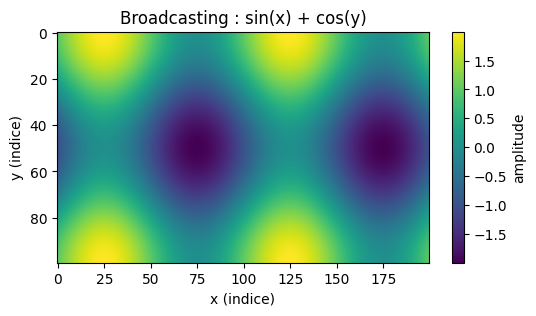

In [46]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 4*np.pi, 200)          # shape (1,200)
y = np.linspace(0, 2*np.pi, 100)[:, None] # shape (100, 1)

Z = np.sin(x) + np.cos(y)                 # shape (100, 200)

print("x.shape =", x.shape)
print("y.shape =", y.shape)
print("Z.shape =", Z.shape)

plt.figure(figsize=(6, 3))
plt.imshow(Z, aspect="auto")
plt.colorbar(label="amplitude")
plt.title("Broadcasting : sin(x) + cos(y)")
plt.xlabel("x (indice)")
plt.ylabel("y (indice)")
plt.show()

# 9. Masques booléens

## Comparaisons et masques

Les comparaisons NumPy produisent des **masques booléens**
qui permettent de filtrer efficacement les données
selon des conditions logiques.


In [11]:
import numpy as np

rng = np.random.default_rng(123)

# Données simulées : pluie quotidienne (en mm) sur une année
pluie_mm = rng.gamma(shape=2.0, scale=2.0, size=365)
print(pluie_mm)

seuil = 5.0
jours_pluie = pluie_mm > seuil
   
print("Nombre de jours avec pluie > 5 mm :", jours_pluie.sum())




[ 1.37614843  7.88715475  6.31862208  1.94525536  2.58088841  3.59056523
  7.45621889  6.64046773  9.06009833  2.59135397  0.26508512  9.10844625
  5.68659589  7.85957287  4.45331607  2.48378885  7.60766227  2.46604655
  6.08294764  6.61211503  5.58894661  8.55633033  1.87877981  3.17739595
 13.43061196  3.418237    3.40686581  2.23813756  1.56602058  3.92360831
  2.11853245  2.58113361  0.8301476   4.60016116  4.16100735  2.8162042
  6.44896065  9.95219198  2.20232574  3.6758167   1.97422661  9.62337617
  1.92459051  1.36756261  4.54737775  7.6450887   4.73628594  8.01502254
  2.6093035   5.95428211  2.17109893  2.62320747  2.65870786  2.76402329
  6.0656342   8.34485629  2.45000615  1.92739993  2.6495732   1.94485007
  5.8074227   2.7154952   4.03328148  4.21310441  4.03496529  2.60575983
  8.47763465 10.03798837  3.5276441   7.5490927   2.8347095   4.31340249
  1.93479912  6.61535963  9.22180208  2.94699398  2.08620224  4.72131975
  2.49117045  4.42981519  3.47530719  2.82786105  3.

## Opérateurs booléens

Les masques booléens peuvent être combinés à l’aide
des opérateurs logiques **bit à bit** :

- `&` : ET
- `|` : OU
- `~` : NON

⚠️ Toujours utiliser des **parenthèses** pour expliciter la logique.


In [49]:
# Masques booléens
grand = heights > 185
petit = heights < 170

print("Très grands :", grand.sum())
print("Petits      :", petit.sum())
print("Grands OU petits :", (grand | petit).sum())


Très grands : 8
Petits      : 3
Grands OU petits : 11


# 10. Fancy indexing

## Sélection par tableaux d’indices

Le *fancy indexing* permet de sélectionner des éléments
à l’aide d’un **tableau d’indices**, même s’ils ne sont pas contigus
ou s’ils sont répétés.


In [ ]:
x = np.arange(10,20)
indices = [1, 3, 7, 9]

print("x        :", x)
print("indices  :", indices)
print("x[indices] :", x[indices])


## Exemple : points aléatoires en 2D

Le *fancy indexing* permet de sélectionner
un sous-ensemble de points non contigus,
par exemple pour les mettre en évidence sur un graphique.


In [ ]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

# 100 points aléatoires en 2D
points = rng.random((100, 2))

# Indices de 10 points choisis aléatoirement
idx = rng.integers(0, 100, size=10)

plt.figure(figsize=(4, 4))
plt.scatter(points[:, 0], points[:, 1], s=20, alpha=0.6, label="Tous les points")
plt.scatter(points[idx, 0], points[idx, 1], s=60, color="red", label="Points sélectionnés")
plt.title("Fancy indexing : points sélectionnés")
plt.legend()
plt.show()


## Modifier des valeurs avec le fancy indexing

Le *fancy indexing* permet de **modifier simultanément**
plusieurs positions spécifiques d’un tableau.


In [ ]:
x = np.zeros(10, dtype=int)
idx = [2, 4, 6, 8]

x[idx] = 1
print(x)


## Exemple : binning de données

Le *binning* consiste à regrouper des valeurs continues
dans des **classes discrètes** (intervalles).


In [ ]:
import numpy as np

rng = np.random.default_rng(0)

# Données continues
mesures = rng.normal(loc=0.0, scale=1.0, size=1000)

# Définition des bornes des classes
bins = np.linspace(-3, 3, 7)

# Indice de classe pour chaque valeur
indices = np.searchsorted(bins, mesures)

# Comptage du nombre de valeurs par classe
compte = np.bincount(indices, minlength=len(bins) + 1)

print("bins   :", bins)
print("compte :", compte)


# 11. Tri et partition

## Tri simple

NumPy fournit deux fonctions principales pour trier des données :

- `np.sort` : trie les valeurs
- `np.argsort` : retourne les indices du tri

In [ ]:
x = rng.integers(0, 100, size=10)

print("x        :", x)
print("sorted   :", np.sort(x))
print("argsort  :", np.argsort(x))


## Tri partiel (partition)

Le tri partiel permet de trouver les *k* plus petits (ou plus grands)
éléments **sans trier entièrement** le tableau.

C’est plus efficace qu’un tri complet lorsque *k* est petit.


In [ ]:
x = rng.integers(0, 100, size=20)
k = 5

idx = np.argpartition(x, k)[:k]

print("x :", x)
print("k plus petits éléments :", x[idx])


## Exemple : k plus proches voisins (kNN)

Recherche des *k* points les plus proches
d’un point de référence.

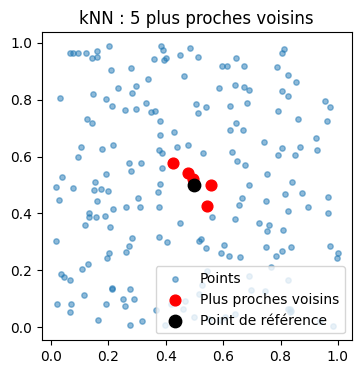

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

# Points aléatoires en 2D
points = rng.random((200, 2))
ref = np.array([0.5, 0.5])

# Distances euclidiennes (au carré)
sq_dist = np.sum((points - ref) ** 2, axis=1)

# Indices des 5 plus proches voisins
idx = np.argsort(sq_dist)[:5]

plt.figure(figsize=(4, 4))
plt.scatter(points[:, 0], points[:, 1], s=15, alpha=0.5, label="Points")
plt.scatter(points[idx, 0], points[idx, 1], s=60, color="red", label="Plus proches voisins")
plt.scatter(ref[0], ref[1], s=80, color="black", label="Point de référence")
plt.title("kNN : 5 plus proches voisins")
plt.legend()
plt.show()


# 12. Données structurées

## Création de tableaux structurés

Un tableau structuré NumPy permet de stocker
des données hétérogènes, organisées en **champs nommés**,
chacun avec son propre `dtype`.

In [ ]:
dtype = [
    ('id', 'U4'),        # identifiant (chaîne Unicode)
    ('temp_moy', 'f4'),  # température moyenne (float)
    ('etat', 'U8')       # état (chaîne)
]

records = np.array([
    ('C01', 62.5, 'ok'),
    ('C02', 71.2, 'alerte'),
    ('C03', 64.8, 'ok')
], dtype=dtype)

print("Tableau structuré :")
print(records)

print("\nChamp 'id' :")
print(records['id'])

print("\nChamp 'temp_moy' :")
print(records['temp_moy'])


## Record arrays

Les *record arrays* sont une vue particulière des tableaux structurés
qui permettent un **accès aux champs par attribut**,
pour une lecture plus lisible.


In [ ]:
rec = records.view(np.recarray)
print(rec.id)
print(rec.temp_moy)

# 13. Exercices et synthése

## Exercices (10 min)
1. Générer un tableau 2D (10x10) de nombres aléatoires uniformes.
2. Extraire la diagonale et calculer sa moyenne.
3. Normaliser les colonnes (soustraire la moyenne, diviser par l'écart-type).
4. Identifier les valeurs > 2 écarts-types (masque).

In [9]:
# A vous de jouer
rng = np.random.default_rng()
X = rng.integers(0,101,size=(10,10))
#print(X)
diag = np.diag(X)
mean_diag = diag.mean()
print(diag)
print(mean_diag)
X_meanCol = X.mean(axis= 0)
X_stdCol = X.std(axis= 0)
X_norm = (X - X_meanCol)/X_stdCol
#print(X_norm)
# mask = ...
mask = X_norm > 2*X_norm.std()
print(mask)

[11 37 53 14 78 31 69 62 41 22]
41.8
[[False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False  True False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]]


## Synthése

- NumPy = mémoire contigué + dtype fixe
- Vectorisation et broadcasting = performance
- Indexation, masques, tri = outils essentiels
- Structures = transition vers pandas

## Pour aller plus loin

- Refaire les exemples avec `%timeit` pour mesurer précisément les performances
- Explorer le module `np.linalg` pour l’algèbre linéaire
- Étudier `np.random` pour la génération de données
- Lire la documentation officielle NumPy

- Refaire les exemples en modifiant les dimensions
- Mesurer les performances avec `%timeit`
- Explorer `np.linalg` pour l’algèbre linéaire